# Volume 15, Appendix J: Birch and Swinnerton-Dyer (Python companion)

Exercises first, solutions at the end. We count points on elliptic curves modulo every prime below $10^5$, check Theorem 10.4 and the
lemmas behind it, redo the experiment of Birch and Swinnerton-Dyer (Figure 10.1), compare the $a_p$ of a curve with complex multiplication and of
one without (Figure 10.2), and compute $L(E,1)$ and the real period for two curves of rank $0$. We use `numpy`, `mpmath` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time, cmath
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

## Exercises

**P10.1 (★) Counting points.** Write a function that returns $a_p=p-\#\{(x,y):y^2+a_1xy+a_3y=x^3+a_2x^2+a_4x+a_6\}$ modulo $p$, vectorised with `numpy`.
For $y^2=x^3-x$ and every prime $3\le p<10^5$, check Theorem 10.4 and Lemma 10.3.

**P10.2 (★★) The experiment.** For the curves of Figure 10.1 (conductors $32$, $37$, $389$, $5077$), plot $\log\prod_{p\le x}N_p/p$ against
$\log\log x$ for $x<10^5$, and fit slopes over $10^3<p<10^5$.

**P10.3 (★★) CM or not.** For $y^2=x^3-x$ and for the curve $y^2+y=x^3-x$ of conductor $37$, compute the proportion of $a_p=0$, the histograms of
$a_p/(2\sqrt p)$, and the moments of $t_p=a_p/\sqrt p$ of Exercise 10.8.

**P10.4 (★★) $L(E,1)$ and the period.** For a curve of rank $0$ with root number $+1$ and conductor $N$, $L(E,1)=2\sum_{n\ge1}\frac{a_n}ne^{-2\pi n/\sqrt N}$.
Compute it for $y^2+y=x^3-x^2$ ($N=11$) and $y^2=x^3-x$ ($N=32$), with the $a_n$ of Proposition 10.5, then the real period
$\Omega=\int_{E(\R)}\bigl|\frac{dx}{2y+a_1x+a_3}\bigr|$ and the quotient $L(E,1)/\Omega$.

**P10.5 (★) Jacobi sums.** Check Lemmas 10.1 and 10.2 for every $p\equiv1\pmod4$ below $2000$, and the formulas of
Exercises 10.4 and 10.5 on small primes.

## Solutions

### P10.1
For each $x$, the equation in $y$ is quadratic; after completing the square ($p$ odd) the number of solutions is $1+\rho(\text{discriminant})$. So
$\#\text{affine}=p+\sum_x\rho\bigl((a_1x+a_3)^2+4(x^3+a_2x^2+a_4x+a_6)\bigr)$, and a table of squares gives $\rho$ in one `numpy` lookup.

In [2]:
def primes_upto(n):
    s = np.ones(n + 1, bool); s[:2] = False
    for i in range(2, int(n**.5) + 1):
        if s[i]: s[i*i::i] = False
    return np.nonzero(s)[0]

def ap(coeffs, p):
    a1, a2, a3, a4, a6 = coeffs
    x = np.arange(p, dtype=np.int64)
    if p == 2:
        return 2 - sum((y*y + a1*xx*y + a3*y - (xx**3 + a2*xx*xx + a4*xx + a6)) % 2 == 0 for xx in range(2) for y in range(2))
    leg = -np.ones(p, np.int64); leg[0] = 0; leg[(x[1:]**2) % p] = 1
    d = ((a1*x + a3)**2 + 4*((((x*x) % p)*x) % p + a2*x*x + a4*x + a6)) % p
    return -int(leg[d].sum())

E1 = (0, 0, 0, -1, 0)
P = primes_upto(10**5)
t0 = time.time()
bad = []
for p in P[1:]:
    p = int(p); a = ap(E1, p); N = p + 1 - a
    if p % 4 == 3:
        ok = (a == 0)
    else:
        u = next(u for u in range(1, int(p**.5) + 1, 2) if math.isqrt(p - u*u)**2 == p - u*u)
        if u % 4 != ((p + 1)//2) % 4: u = -u
        ok = (a == 2*u) and N % 8 == 0
    if not ok: bad.append(p)
print('%d odd primes checked in %.1f s; failures: %s' % (len(P) - 1, time.time() - t0, bad))
print('first values:', [(int(p), ap(E1, int(p))) for p in P[1:12]])

9591 odd primes checked in 19.4 s; failures: []
first values: [(3, 0), (5, -2), (7, 0), (11, 0), (13, 6), (17, 2), (19, 0), (23, 0), (29, -10), (31, 0), (37, -2)]


No failures: for every odd prime below $10^5$, $a_p=0$ when $p\equiv3\pmod4$, and otherwise $a_p=2a$ with $p=a^2+b^2$, $a\equiv\frac{p+1}2\pmod4$, and
$8\mid N_p$. The list starts $a_3=0$, $a_5=-2$, $a_7=0$, $a_{11}=0$, $a_{13}=6$, $a_{17}=2$, as in Exercise 10.1.

### P10.2
The four curves, in the notation $[a_1,a_2,a_3,a_4,a_6]$, and their bad primes (the primes dividing the conductor).

point counts: 71 s
rank 0, y^2=x^3-x        value at 10^5: 0.712   slope over 10^3<p<10^5: -0.06
rank 1, conductor 37     value at 10^5: 4.525   slope over 10^3<p<10^5: 1.07
rank 2, conductor 389    value at 10^5: 6.719   slope over 10^3<p<10^5: 2.03
rank 3, conductor 5077   value at 10^5: 8.825   slope over 10^3<p<10^5: 2.64


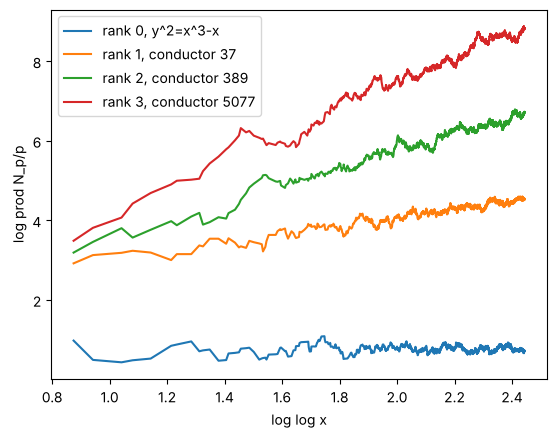

In [3]:
curves = {'rank 0, y^2=x^3-x': ((0, 0, 0, -1, 0), {2}),
          'rank 1, conductor 37': ((0, 0, 1, -1, 0), {37}),
          'rank 2, conductor 389': ((0, 1, 1, -2, 0), {389}),
          'rank 3, conductor 5077': ((0, 0, 1, -7, 6), {5077})}
AP = {}
t0 = time.time()
for name, (c, badp) in curves.items():
    AP[name] = np.array([ap(c, int(p)) for p in P])
print('point counts: %.0f s' % (time.time() - t0))
for name, (c, badp) in curves.items():
    a = AP[name]; good = np.array([int(p) not in badp for p in P])
    S = np.cumsum(np.where(good, np.log((P + 1 - a) / P), 0.0))
    m = P >= 10
    plt.plot(np.log(np.log(P[m])), S[m], label=name)
    w = P > 1000
    print('%-24s value at 10^5: %.3f   slope over 10^3<p<10^5: %.2f' % (name, S[-1], np.polyfit(np.log(np.log(P[w])), S[w], 1)[0]))
plt.xlabel('log log x'); plt.ylabel('log prod N_p/p'); plt.legend(); plt.show()

The curves are sorted by rank, with slopes close to $0$, $1$, $2$, $3$ but not equal to them, and the slopes shift by a few tenths if you change the
window (try $p>10^4$). Over the range of Figure 10.1, up to $2\cdot10^5$, the book finds $-0.00$, $1.03$, $2.17$, $2.91$. The experiment is
suggestive and nothing more: $\log\log x$ only goes from $1.9$ to $2.4$ here.

### P10.3

rank 0, y^2=x^3-x        P(a_p=0) = 0.5013   E[t^2] = 0.9980   E[t^4] = 2.9916


rank 1, conductor 37     P(a_p=0) = 0.0032   E[t^2] = 0.9955   E[t^4] = 1.9891


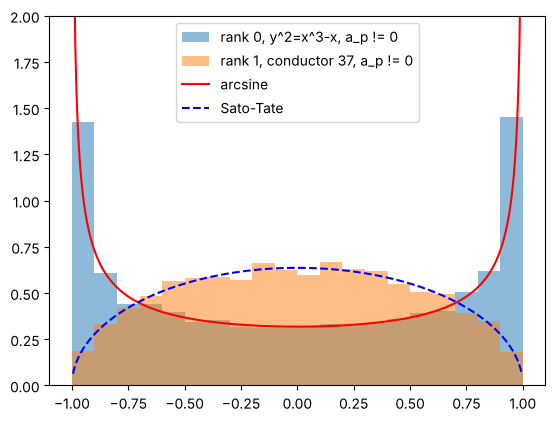

In [4]:
odd = P > 2
for name in ['rank 0, y^2=x^3-x', 'rank 1, conductor 37']:
    a = AP[name][odd]; p = P[odd]
    keep = p != (37 if '37' in name else 0)
    a, p = a[keep], p[keep]
    t = a / np.sqrt(p)
    print('%-24s P(a_p=0) = %.4f   E[t^2] = %.4f   E[t^4] = %.4f' % (name, np.mean(a == 0), np.mean(t**2), np.mean(t**4)))
    plt.hist(a[a != 0] / (2*np.sqrt(p[a != 0])), bins=20, range=(-1, 1), density=True, alpha=0.5, label=name + ', a_p != 0')
xs = np.linspace(-0.995, 0.995, 400)
plt.plot(xs, 1/(np.pi*np.sqrt(1 - xs**2)), 'r', label='arcsine')
plt.plot(xs, 2/np.pi*np.sqrt(1 - xs**2), 'b--', label='Sato-Tate')
plt.ylim(0, 2); plt.legend(); plt.show()

For the CM curve, half the $a_p$ vanish (Corollary 10.6), the others follow the arcsine law, and the moments are close to $1$ and $3$. For the
curve of conductor $37$, which has no complex multiplication, $a_p=0$ is rare (Serre: density $0$), the histogram follows the semicircle, and the
moments are close to $1$ and $2$. Both curves have the same second moment, as Exercise 10.8 predicts.

### P10.4
The coefficients come from the recursion of Proposition 10.5 at each prime and multiplicativity. For the period: with $Y=2y+a_1x+a_3$ the
equation becomes $Y^2=g(x)$ with $g=4x^3+b_2x^2+2b_4x+b_6$, the differential is $dx/Y$, and each real component contributes $2\int_e^\infty dx/\sqrt{g}$,
where $e$ is the largest real root of $g$. When $g$ has three real roots there are two components with the same period.

In [5]:
def an_list(coeffs, M, badp):
    a = np.zeros(M + 1, dtype=np.int64); a[1] = 1
    spf = np.arange(M + 1)
    for i in range(2, int(M**.5) + 1):
        if spf[i] == i:
            for j in range(i*i, M + 1, i):
                if spf[j] == j: spf[j] = i
    pk = {}
    for p in primes_upto(M):
        p = int(p); e = 0 if p in badp else 1
        pk[(p, 0)] = 1; pk[(p, 1)] = ap(coeffs, p); k, q = 1, p
        while q * p <= M:
            k += 1; q *= p
            pk[(p, k)] = pk[(p, 1)] * pk[(p, k - 1)] - e * p * pk[(p, k - 2)]
    for n in range(2, M + 1):
        p = int(spf[n]); m, k = n, 0
        while m % p == 0: m //= p; k += 1
        a[n] = pk[(p, k)] * a[m]
    return a

def L1(coeffs, N, badp, M=3000):
    a = an_list(coeffs, M, badp); n = np.arange(1, M + 1)
    return 2 * float(np.sum(a[1:] / n * np.exp(-2*np.pi*n/np.sqrt(N))))

def period(coeffs):
    a1, a2, a3, a4, a6 = coeffs
    b2, b4, b6 = a1*a1 + 4*a2, 2*a4 + a1*a3, a3*a3 + 4*a6
    g = lambda x: 4*x**3 + b2*x**2 + 2*b4*x + b6
    roots = [r for r in np.roots([4, b2, 2*b4, b6]) if abs(r.imag) < 1e-9]
    e = max(r.real for r in roots)
    one = 2 * mp.quad(lambda x: 1/mp.sqrt(g(x)), [e, e + 1, mp.inf])
    return float(mp.re(one)) * (2 if len(roots) == 3 else 1)

for name, c, N, badp, tors in [('y^2+y=x^3-x^2', (0, -1, 1, 0, 0), 11, {11}, 5), ('y^2=x^3-x', (0, 0, 0, -1, 0), 32, {2}, 4)]:
    L, Om = L1(c, N, badp), period(c)
    print('%-15s a_1..a_12 = %s' % (name, [int(v) for v in an_list(c, 12, badp)[1:]]))
    print('%-15s L(E,1) = %.8f   Omega = %.8f   L/Omega = %.8f   |T|^2 * L/Omega = %.6f' % (name, L, Om, L/Om, tors**2 * L/Om))

y^2+y=x^3-x^2   a_1..a_12 = [1, -2, -1, 2, 1, 2, -2, 0, -2, -2, 1, -2]
y^2+y=x^3-x^2   L(E,1) = 0.25384186   Omega = 6.34604652   L/Omega = 0.04000000   |T|^2 * L/Omega = 1.000000


y^2=x^3-x       a_1..a_12 = [1, 0, 0, 0, -2, 0, 0, 0, -3, 0, 0, 0]
y^2=x^3-x       L(E,1) = 0.65551439   Omega = 5.24411511   L/Omega = 0.12500000   |T|^2 * L/Omega = 2.000000


For $y^2+y=x^3-x^2$, $L(E,1)=0.25384186\ldots$ (the value quoted in Volume 12), $\Omega=6.34604652\ldots$, and $L/\Omega=\frac1{25}$; its coefficients agree
with those of $\eta(\tau)^2\eta(11\tau)^2$ (Exercise 10.6). For $y^2=x^3-x$, $L/\Omega=\frac18$, so the conjectured formula asks
$|\text{Ш}|\prod_pc_p=16\cdot\frac18=2$. Both quotients are rational to eight digits, which is what Birch and Swinnerton-Dyer first noticed for the curves
$y^2=x^3-Dx$. (The series is valid because these curves have root number $+1$; for root number $-1$ the same series gives $0$ automatically.)

### P10.5

In [6]:
def char(p, order):
    # a character of the given order: send a primitive root g to exp(2 pi i / order)
    fac = [q for q in range(2, p) if (p - 1) % q == 0 and all(q % r for r in range(2, int(q**.5) + 1))]
    g = next(g for g in range(2, p) if all(pow(g, (p - 1)//q, p) != 1 for q in fac))
    lg = {pow(g, k, p): k for k in range(p - 1)}
    w = cmath.exp(2j*cmath.pi/order)
    return lambda u: 0 if u % p == 0 else w**(lg[u % p] % order)

def J(c1, c2, p): return sum(c1(u) * c2(1 - u) for u in range(p))

bad = []
for p in [int(q) for q in primes_upto(2000) if q % 4 == 1]:
    chi, rho = char(p, 4), char(p, 2)
    j = J(chi, rho, p)
    if abs(abs(j)**2 - p) > 1e-6 or abs(-2*j.real - ap(E1, p)) > 1e-6: bad.append(p)
print('p = 1 mod 4 below 2000: failures', bad)
chi, rho = char(13, 4), char(13, 2)
print('p = 13, chi(2) =', np.round(chi(2), 6), ' J(chi, rho) =', np.round(J(chi, rho, 13), 6))
worst = 0
for p in [13, 17, 29, 37, 41, 53]:
    chi, rho = char(p, 4), char(p, 2); j = J(chi, rho, p)
    for D in (1, -1, 2, -2, 3):
        worst = max(worst, abs(ap((0, 0, 0, -D, 0), p) + 2*(chi(D).conjugate()*j).real))
for p in [7, 13, 19, 31, 37]:
    psi, rho = char(p, 3), char(p, 2); j = J(psi, rho, p)
    for D in (1, 2, 3, 5):
        worst = max(worst, abs(ap((0, 0, 0, 0, D), p) + 2*(psi(D)*rho(D)*j).real))
print('largest error in the formulas of the two exercises:', worst)

p = 1 mod 4 below 2000: failures []
p = 13, chi(2) = 1j  J(chi, rho) = (-3+2j)
largest error in the formulas of the two exercises: 1.0658141036401503e-14


All checks pass. For $p=13$ the generator found is $2$, with $\chi(2)=i$, and $J(\chi,\rho)=-3+2i$, as in Exercise 10.3. (For other $p$ the
generator chosen, hence $\chi$, may differ from yours; $J(\chi,\rho)$ then changes to its conjugate, which does not change $a_p$.)